# 02 – Mask classification on LAS tiles (Site 1)

This notebook applies mask-based classification to clipped LiDAR coregistered point clouds LAS tiles using PDAL pipelines.
This notebook mirrors the `clipping_toMask_coreg.py` workflow using the packaged `maskclip` functions.

Sequential processing to classify LAS points using raster masks.

- Crops to raster bounds
- Applies mask-driven classification (values 64-68)
- Preserves original scale/offset and metadata

In [6]:
from pathlib import Path

# --- CONFIGURATION: Site 2 (DD0011) ---
SITE_NAME = 'site2_DD0011'


# LiDAR ICP registered + mask classification
LAS_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/raster/coreg/icp")
AOI_RASTER_DIR = Path("/data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/stacked")
MASK_DIR = Path("/data/calperumResearch/site2_1_DD0011/imagery/inputs/masks/tiles_3072/structure_class/annotation_raster/downsample_5cm_nearest")


# If LAS_DIR was set to a specific LAS file path, normalize to its parent directory
if LAS_DIR.is_file():
    print(f"Note: LAS_DIR points to a file. Using parent folder: {LAS_DIR.parent}")
    LAS_DIR = LAS_DIR.parent

# Pattern for LAS tiles produced by rasterclip
RASTER_PATTERN = 'tiles_multispectral*.las'

# Single tile example
TILE_ID = '33'
A_TILE = AOI_RASTER_DIR / f'tiles_multispectral.{TILE_ID}.tif'

# Output directory for mask classification
OUT_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/mask/coreg/icp_top")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('--- Configuration ---')
print(f'Raster dir  : {AOI_RASTER_DIR}')
print(f'Mask dir    : {MASK_DIR}')
print(f'LAS dir     : {LAS_DIR}')
print(f'Pattern     : {RASTER_PATTERN}')
print(f'Single tile : {TILE_ID}')
print(f'Output dir  : {OUT_DIR}')
print('----------------------')

--- Configuration ---
Raster dir  : /data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/stacked
Mask dir    : /data/calperumResearch/site2_1_DD0011/imagery/inputs/masks/tiles_3072/structure_class/annotation_raster/downsample_5cm_nearest
LAS dir     : /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/raster/coreg/icp
Pattern     : tiles_multispectral*.las
Single tile : 33
Output dir  : /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/mask/coreg/icp_top
----------------------


In [2]:
# --- Single tile classification (optional; for testing) ---
import time
from pathlib import Path
from maskclip import classify_single

# Single tile example
TILE_ID = '33'
A_LAS = LAS_DIR / f'tiles_multispectral.{TILE_ID}.las'
A_RASTER = AOI_RASTER_DIR / f'tiles_multispectral.{TILE_ID}.tif'
A_MASK = MASK_DIR / f'mask_structure_3072.{TILE_ID}.tif'
out_single = OUT_DIR / f'mask_tiles_multispectral.{TILE_ID}.las'

if A_LAS.exists() and A_RASTER.exists() and A_MASK.exists():
    print('Starting single-tile classification...')
    t0 = time.time()
    pts = classify_single(A_LAS, A_RASTER, A_MASK, out_single)
    dt = time.time() - t0
    print(f'✅ Single tile written: {out_single} ({pts} points) in {dt:.2f}s')
    print('Tip: If single-tile is slow, run batch processing for better throughput.')
else:
    print(f'⚠️  Skipping single tile: missing input files')
    print(f'  LAS exists: {A_LAS.exists()}')
    print(f'  Raster exists: {A_RASTER.exists()}')
    print(f'  Mask exists: {A_MASK.exists()}')

Starting single-tile classification...
✅ Single tile written: /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/mask/coreg/icp_top/mask_tiles_multispectral.33.las (461446 points) in 0.88s
Tip: If single-tile is slow, run batch processing for better throughput.


In [3]:
# Option a) Multiple tiles: following clippling_toMask_coreg.py
# --- Sequential mask classification (matching coreg pattern) ---
import json
import pdal
import rasterio
import laspy
from tqdm import tqdm

# Find all LAS files
las_files = sorted(LAS_DIR.glob(RASTER_PATTERN))

if not las_files:
    print(f"❌ No LAS files found in {LAS_DIR}")
else:
    print(f"Found {len(las_files)} LAS files to process")
    
    # Process each file
    for input_las in tqdm(las_files, desc="Processing tiles"):
        # Extract tile ID (e.g., "tiles_multispectral.33.las" -> "33")
        tile_id = input_las.stem.split(".")[-1]
        
        # Construct corresponding raster and mask paths
        aoi_raster_5cm = AOI_RASTER_DIR / f"tiles_multispectral.{tile_id}.tif"
        aoi_mask_tif_5cm = MASK_DIR / f"mask_structure_3072.{tile_id}.tif"
        
        # Validate files exist
        if not aoi_raster_5cm.exists():
            print(f"⚠️  Skipping tile {tile_id}: raster not found")
            continue
        if not aoi_mask_tif_5cm.exists():
            print(f"⚠️  Skipping tile {tile_id}: mask not found")
            continue
        
        # Output file
        raster_name = aoi_raster_5cm.stem
        output_classified_las = OUT_DIR / f"mask_{raster_name}.las"
        
        # Skip if already processed
        if output_classified_las.exists():
            continue
        
        # --- Preserve original scale/offset ---
        in_las = laspy.read(input_las)
        sx, sy, sz = in_las.header.scales
        ox, oy, oz = in_las.header.offsets
        minor_ver = int(in_las.header.version.minor)
        
        # === Read raster bounds ===
        with rasterio.open(aoi_raster_5cm) as src:
            target_epsg = src.crs.to_epsg()
            minx, miny, maxx, maxy = src.bounds
        
        bounds_str = f"([{minx},{maxx}],[{miny},{maxy}])"
        
        # === Build the PDAL pipeline ===
        pipeline = {
            "pipeline": [
                {"type": "readers.las", "filename": str(input_las)},
                {"type": "filters.crop", "bounds": bounds_str},
                {"type": "filters.colorization", "raster": str(aoi_mask_tif_5cm), "dimensions": "Classification"},
                {"type": "filters.range", "limits": "Classification[64:68]"},
                {
                    "type": "writers.las",
                    "filename": str(output_classified_las),
                    "minor_version": minor_ver,
                    "extra_dims": "all",
                    "scale_x": sx, "scale_y": sy, "scale_z": sz,
                    "offset_x": ox, "offset_y": oy, "offset_z": oz,
                    "forward": "all"
                }
            ]
        }
        
        # Execute pipeline
        try:
            pipe = pdal.Pipeline(json.dumps(pipeline))
            n = pipe.execute()
            print(f"✅ Tile {tile_id}: {n:,} points → {output_classified_las.name}")
        except Exception as e:
            print(f"❌ Error processing tile {tile_id}: {e}")
    
    print(f"\n🎉 All processing complete.")

Found 15 LAS files to process


Processing tiles:   7%|▋         | 1/15 [00:00<00:05,  2.39it/s]

✅ Tile 25: 214,634 points → mask_tiles_multispectral.25.las


Processing tiles:  13%|█▎        | 2/15 [00:01<00:06,  1.93it/s]

✅ Tile 30: 209,139 points → mask_tiles_multispectral.30.las


Processing tiles:  20%|██        | 3/15 [00:01<00:08,  1.46it/s]

... (19 outputs left out)

Processing tiles:  93%|█████████▎| 14/15 [00:08<00:00,  1.34it/s]

✅ Tile 75: 101,527 points → mask_tiles_multispectral.75.las


Processing tiles: 100%|██████████| 15/15 [00:09<00:00,  1.58it/s]

✅ Tile 79: 227,889 points → mask_tiles_multispectral.79.las

🎉 All processing complete.


In [9]:
# option b) using maskclip 
# --- Batch classification: Dask-parallel with signature ---
from maskclip import classify_many_dask, classify_single
from pathlib import Path

# Dask-parallel with signature logging
outs_dask = classify_many_dask(
    LAS_DIR,
    AOI_RASTER_DIR,
    MASK_DIR,
    OUT_DIR,
    pattern=RASTER_PATTERN,
    skip_existing=True,
    write_signature=True,
)
print(f'✅ Dask batch outputs: {len(outs_dask)}')

sig_path = OUT_DIR / 'mask_signature.txt'
if sig_path.exists():
    print(f'📝 Signature file: {sig_path}')
    try:
        print(sig_path.read_text())
    except Exception:
        print('Signature written, but could not display contents.')

Dask dashboard: http://172.16.1.208:8787/status


Mask → LAS:  10%|█         | 1/10 [00:00<00:05,  1.63tile/s]

✅ tiles_multispectral.109.las → mask_tiles_multispectral.109.las (23,711 pts)
✅ tiles_multispectral.113.las → mask_tiles_multispectral.113.las (7,365 pts)


Mask → LAS:  30%|███       | 3/10 [00:00<00:01,  3.99tile/s]

✅ tiles_multispectral.182.las → mask_tiles_multispectral.182.las (144,072 pts)


Mask → LAS:  40%|████      | 4/10 [00:02<00:05,  1.19tile/s]

... (5 outputs left out)

Mask → LAS:  80%|████████  | 8/10 [00:03<00:00,  2.46tile/s]

✅ tiles_multispectral.71.las → mask_tiles_multispectral.71.las (483,820 pts)


Mask → LAS: 100%|██████████| 10/10 [00:04<00:00,  2.22tile/s]

✅ tiles_multispectral.93.las → mask_tiles_multispectral.93.las (739,544 pts)
✅ tiles_multispectral.96.las → mask_tiles_multispectral.96.las (1,119,708 pts)
Signature written: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top/mask_signature.txt
✅ Done classifying. Successful: 10, Failed: 0, Elapsed: 5.15s
✅ Dask batch outputs: 10
📝 Signature file: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top/mask_signature.txt
Date: 2026-03-06 04:28:47
LAS dir: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/raster/coreg/icp
Raster dir: /data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked
Mask dir: /data/calperumResearch/site1_1_DD0001/imagery/inputs/masks/tiles_3072/structure_class/annotation_raster/downsample_5cm_nearest
Pattern: tiles_multispectral*.las
Output dir: /data/calperumResearch/site1_1_DD0001/lidar_l2/clipped/mask/coreg/icp_top
Total LAS: 10
Successful: 10
Failed: 0
Elapsed (s): 5.15



In [7]:
# --- Inspect one output LAS ---
import laspy, numpy as np

# pick one output (first matching pattern). Support both naming styles.
candidates = sorted(OUT_DIR.glob(RASTER_PATTERN))
mask_named = sorted(OUT_DIR.glob('mask_tiles_multispectral*.las'))
candidates = mask_named or candidates
sample_out = candidates[0] if candidates else None
print(f'Inspecting: {sample_out}')
if sample_out and sample_out.exists():
    las = laspy.read(sample_out)
    print(f'Total points: {len(las.points):,}')
    print('Bounding box:')
    print(f'  X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}')
    print(f'  Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}')
    print(f'  Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}')
    print(f'Point format: {las.header.point_format}')
    print(f'Extra dims : {[dim.name for dim in las.point_format.extra_dimensions]}')
    if hasattr(las, 'classification'):
        cls = np.asarray(las.classification, dtype=np.uint8)
        unique, counts = np.unique(cls, return_counts=True)
        print('Classification counts:')
        for u, c in zip(unique, counts):
            print(f'  class {int(u)}: {int(c):,}')
else:
    print('No outputs found yet. Ensure fvclip produced LAS tiles and paths match.')

Inspecting: /data/calperumResearch/site2_1_DD0011/lidar_l2/clipped/mask/coreg/icp_top/mask_tiles_multispectral.25.las
Total points: 214,634
Bounding box:
  X: 473284.79 → 473315.47
  Y: 6235833.58 → 6235864.21
  Z: 32.55 → 34.40
Point format: <PointFormat(7, 0 bytes of extra dims)>
Extra dims : []
Classification counts:
  class 64: 71,188
  class 67: 143,446


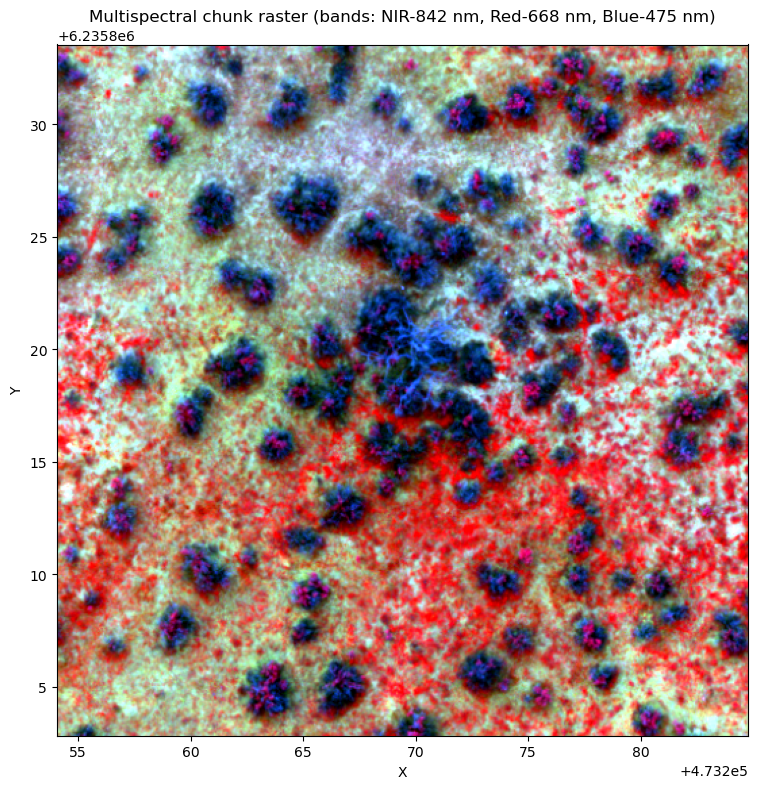

In [8]:
# --- View original raster (bands 5/3/1) ---
import rasterio, numpy as np, matplotlib.pyplot as plt

tile_path = A_TILE
with rasterio.open(tile_path) as src:
    if src.count < 5:
        raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
    b5 = src.read(5).astype(np.float32)
    b3 = src.read(3).astype(np.float32)
    b1 = src.read(1).astype(np.float32)
    def norm_band(b):
        lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
        b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
        b[~np.isfinite(b)] = 0
        return b
    rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(8, 8))
plt.imshow(rgb, extent=extent, origin='upper')
plt.title('Multispectral chunk raster (bands: NIR-842 nm, Red-668 nm, Blue-475 nm)')
plt.xlabel('X'); plt.ylabel('Y')
plt.tight_layout(); plt.show()

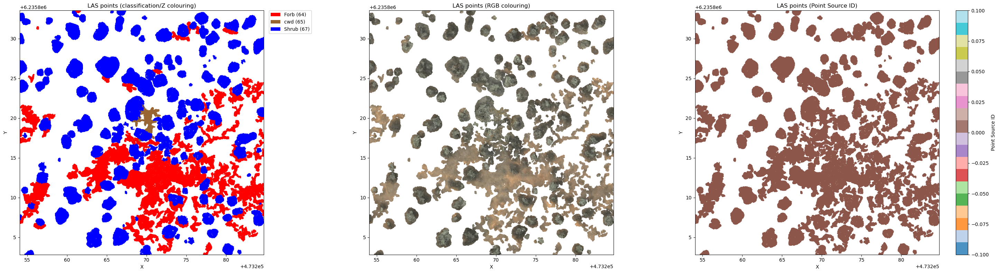

In [9]:
# --- View LAS only (colored by classification if present; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Patch
import rasterio


# Get sample_out from configured TILE_ID or find first available output
try:
    sample_out = OUT_DIR / f'mask_tiles_multispectral.{TILE_ID}.las'
    if not sample_out.exists():
        # Try alternate naming pattern
        sample_out = OUT_DIR / f'tiles_multispectral.{TILE_ID}.las'
    if not sample_out.exists():
        # Find first available output
        candidates = sorted(OUT_DIR.glob('mask_tiles_multispectral*.las'))
        if not candidates:
            candidates = sorted(OUT_DIR.glob('tiles_multispectral*.las'))
        sample_out = candidates[0] if candidates else None
except NameError:
    # TILE_ID not defined, search for any output
    candidates = sorted(OUT_DIR.glob('mask_tiles_multispectral*.las'))
    if not candidates:
        candidates = sorted(OUT_DIR.glob('tiles_multispectral*.las'))
    sample_out = candidates[0] if candidates else None

if sample_out is None:
    raise FileNotFoundError('No LAS output files found. Run classification first.')

las = laspy.read(sample_out)
x = las.x
y = las.y

# Get extent from raster
if sample_out:
    tile_id = sample_out.stem.split('.')[-1]
    raster_extent_path = AOI_RASTER_DIR / f'tiles_multispectral.{tile_id}.tif'
else:
    rlist = sorted(AOI_RASTER_DIR.glob('tiles_multispectral.*.tif'))
    raster_extent_path = rlist[0] if rlist else None

if raster_extent_path and raster_extent_path.exists():
    with rasterio.open(raster_extent_path) as src:
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
else:
    extent = None

if hasattr(las, 'classification'):
    cls = np.asarray(las.classification, dtype=np.uint8)
    # map classes to colors (simple palette)
    # 64=forb, 65=cwd, 66=hummock, 67=shrub, 68=mallee
    palette = {
        64: (1.0, 0.0, 0.0),    # forb - red
        65: (0.6, 0.4, 0.2),    # cwd - brown
        66: (0.0, 1.0, 0.0),    # hummock - green
        67: (0.0, 0.0, 1.0),    # shrub - blue
        68: (1.0, 1.0, 0.0)     # mallee - yellow
    }
    class_labels = {
        64: 'Forb',
        65: 'cwd',
        66: 'Hummock',
        67: 'Shrub',
        68: 'Mallee'
    }
    colors = np.array([palette.get(int(c), (0.5, 0.5, 0.5)) for c in cls], dtype=np.float32)
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]
    if hasattr(las, 'classification'):
        cls = cls[idx]
else:
    idx = None

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(30, 8))
plt.subplots_adjust(wspace=0.05)

# Plot 1: Classification/Z coloring
ax = axes[0]
ax.set_title('LAS points (classification/Z colouring)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if colors.ndim == 2:
    ax.scatter(x, y, s=2, c=colors, alpha=0.8)
    # Add legend for classification colors
    if hasattr(las, 'classification'):
        unique_classes = np.unique(cls)
        legend_elements = [Patch(facecolor=palette.get(int(c), (0.5, 0.5, 0.5)), 
                                 label=f"{class_labels.get(int(c), f'Class {int(c)}')} ({int(c)})")
                          for c in unique_classes if int(c) in palette]
        ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), 
                  framealpha=0.9, borderaxespad=0)
else:
    sc = ax.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
    fig.colorbar(sc, ax=ax, label='Z elevation (normalized)')

# Plot 2: RGB coloring (if available)
ax = axes[1]
ax.set_title('LAS points (RGB colouring)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue'):
    if idx is not None:
        r = np.asarray(las.red[idx], dtype=np.float32) / 65535.0
        g = np.asarray(las.green[idx], dtype=np.float32) / 65535.0
        b = np.asarray(las.blue[idx], dtype=np.float32) / 65535.0
    else:
        r = np.asarray(las.red, dtype=np.float32) / 65535.0
        g = np.asarray(las.green, dtype=np.float32) / 65535.0
        b = np.asarray(las.blue, dtype=np.float32) / 65535.0
    rgb_colors = np.stack([r, g, b], axis=-1)
    ax.scatter(x, y, s=2, c=rgb_colors, alpha=0.8)
else:
    ax.text(0.5, 0.5, 'RGB not available', ha='center', va='center', transform=ax.transAxes)
    if not extent:
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(y.min(), y.max())

# Plot 3: Point Source ID
ax = axes[2]
ax.set_title('LAS points (Point Source ID)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if hasattr(las, 'point_source_id'):
    if idx is not None:
        ps_id = np.asarray(las.point_source_id[idx], dtype=np.int32)
    else:
        ps_id = np.asarray(las.point_source_id, dtype=np.int32)
    sc = ax.scatter(x, y, s=2, c=ps_id, cmap='tab20', alpha=0.8)
    fig.colorbar(sc, ax=ax, label='Point Source ID')
else:
    ax.text(0.5, 0.5, 'Point Source ID not available', ha='center', va='center', transform=ax.transAxes)
    if not extent:
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(y.min(), y.max())

plt.tight_layout(); plt.show()

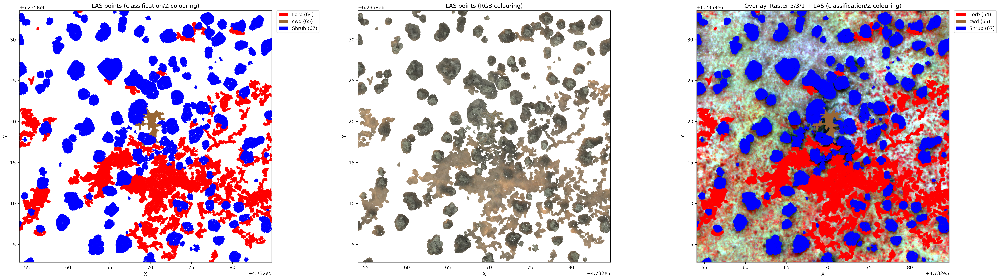

In [10]:
# --- View LAS only (colored by classification if present; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Patch
import rasterio


# Get sample_out from configured TILE_ID or find first available output
try:
    sample_out = OUT_DIR / f'mask_tiles_multispectral.{TILE_ID}.las'
    if not sample_out.exists():
        # Try alternate naming pattern
        sample_out = OUT_DIR / f'tiles_multispectral.{TILE_ID}.las'
    if not sample_out.exists():
        # Find first available output
        candidates = sorted(OUT_DIR.glob('mask_tiles_multispectral*.las'))
        if not candidates:
            candidates = sorted(OUT_DIR.glob('tiles_multispectral*.las'))
        sample_out = candidates[0] if candidates else None
except NameError:
    # TILE_ID not defined, search for any output
    candidates = sorted(OUT_DIR.glob('mask_tiles_multispectral*.las'))
    if not candidates:
        candidates = sorted(OUT_DIR.glob('tiles_multispectral*.las'))
    sample_out = candidates[0] if candidates else None

if sample_out is None:
    raise FileNotFoundError('No LAS output files found. Run classification first.')


las = laspy.read(sample_out)
x = las.x
y = las.y

# Get extent from raster
if sample_out:
    tile_id = sample_out.stem.split('.')[-1]
    raster_extent_path = AOI_RASTER_DIR / f'tiles_multispectral.{tile_id}.tif'
else:
    rlist = sorted(AOI_RASTER_DIR.glob('tiles_multispectral.*.tif'))
    raster_extent_path = rlist[0] if rlist else None

if raster_extent_path and raster_extent_path.exists():
    with rasterio.open(raster_extent_path) as src:
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
        # Load raster bands for overlay in third panel
        if src.count < 5:
            raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
        b5 = src.read(5).astype(np.float32)
        b3 = src.read(3).astype(np.float32)
        b1 = src.read(1).astype(np.float32)
        def norm_band(b):
            lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
            b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
            b[~np.isfinite(b)] = 0
            return b
        rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
else:
    extent = None
    rgb = None

if hasattr(las, 'classification'):
    cls = np.asarray(las.classification, dtype=np.uint8)
    # map classes to colors (simple palette)
    # 64=forb, 65=cwd, 66=hummock, 67=shrub, 68=mallee
    palette = {
        64: (1.0, 0.0, 0.0),    # forb - red
        65: (0.6, 0.4, 0.2),    # cwd - brown
        66: (0.0, 1.0, 0.0),    # hummock - green
        67: (0.0, 0.0, 1.0),    # shrub - blue
        68: (1.0, 1.0, 0.0)     # mallee - yellow
    }
    class_labels = {
        64: 'Forb',
        65: 'cwd',
        66: 'Hummock',
        67: 'Shrub',
        68: 'Mallee'
    }
    colors = np.array([palette.get(int(c), (0.5, 0.5, 0.5)) for c in cls], dtype=np.float32)
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]
    if hasattr(las, 'classification'):
        cls = cls[idx]
else:
    idx = None

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(30, 8), dpi=300)
plt.subplots_adjust(wspace=0, hspace=0)

# Plot 1: Classification/Z coloring
ax = axes[0]
ax.set_title('LAS points (classification/Z colouring)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if colors.ndim == 2:
    ax.scatter(x, y, s=2, c=colors, alpha=0.8)
    # Add legend for classification colors
    if hasattr(las, 'classification'):
        unique_classes = np.unique(cls)
        legend_elements = [Patch(facecolor=palette.get(int(c), (0.5, 0.5, 0.5)), 
                                 label=f"{class_labels.get(int(c), f'Class {int(c)}')} ({int(c)})")
                          for c in unique_classes if int(c) in palette]
        ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), 
                  framealpha=0.9, borderaxespad=0)
else:
    sc = ax.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
    fig.colorbar(sc, ax=ax, label='Z elevation (normalized)')

# Plot 2: RGB coloring (if available)
ax = axes[1]
ax.set_title('LAS points (RGB colouring)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue'):
    if idx is not None:
        r = np.asarray(las.red[idx], dtype=np.float32) / 65535.0
        g = np.asarray(las.green[idx], dtype=np.float32) / 65535.0
        b = np.asarray(las.blue[idx], dtype=np.float32) / 65535.0
    else:
        r = np.asarray(las.red, dtype=np.float32) / 65535.0
        g = np.asarray(las.green, dtype=np.float32) / 65535.0
        b = np.asarray(las.blue, dtype=np.float32) / 65535.0
    rgb_colors = np.stack([r, g, b], axis=-1)
    ax.scatter(x, y, s=2, c=rgb_colors, alpha=0.8)
else:
    ax.text(0.5, 0.5, 'RGB not available', ha='center', va='center', transform=ax.transAxes)
    if not extent:
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(y.min(), y.max())

# Plot 3: Overlay - Raster 5/3/1 + LAS (classification/Z coloring)
ax = axes[2]
ax.set_title('Overlay: Raster 5/3/1 + LAS (classification/Z colouring)')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
if rgb is not None:
    ax.imshow(rgb, extent=extent, origin='upper')
if colors.ndim == 2:
    ax.scatter(x, y, s=2, c=colors, alpha=0.7)
    # Add legend for classification colors
    if hasattr(las, 'classification'):
        unique_classes = np.unique(cls)
        legend_elements = [Patch(facecolor=palette.get(int(c), (0.5, 0.5, 0.5)), 
                                 label=f"{class_labels.get(int(c), f'Class {int(c)}')} ({int(c)})")
                          for c in unique_classes if int(c) in palette]
        ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), 
                  framealpha=0.9, borderaxespad=0)
else:
    ax.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.7)

plt.tight_layout(pad=0, w_pad=0, h_pad=0); plt.show()


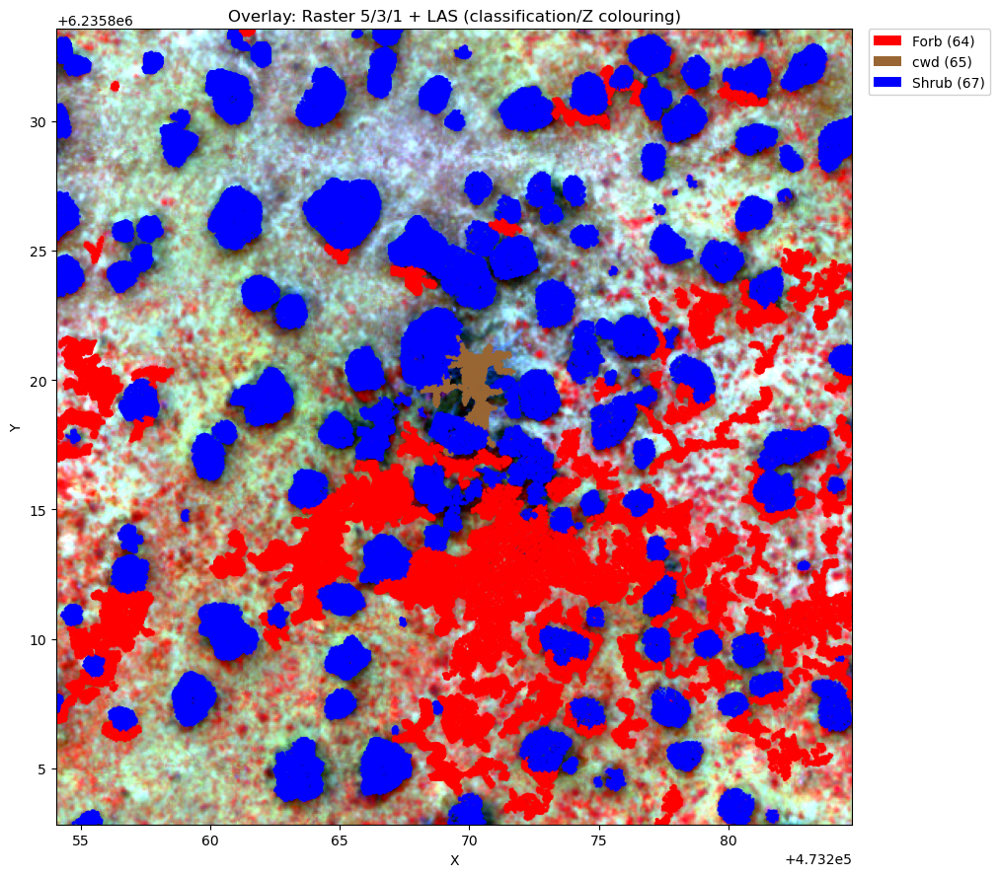

In [11]:
# --- Overlay: Raster 5/3/1 + LAS (classification/Z coloring) ---
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(rgb, extent=extent, origin='upper')
ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Overlay: Raster 5/3/1 + LAS (classification/Z colouring)')

# reuse colors from previous cell if available
try:
    cvals = colors
except NameError:
    import numpy as np, laspy
    las = laspy.read(sample_out)
    x = las.x; y = las.y
    if hasattr(las, 'classification'):
        cls = np.asarray(las.classification, dtype=np.uint8)
        palette = {
            64: (1.0, 0.0, 0.0),    # forb - red
            65: (0.6, 0.4, 0.2),    # cwd - brown
            66: (0.0, 1.0, 0.0),    # hummock - green
            67: (0.0, 0.0, 1.0),    # shrub - blue
            68: (1.0, 1.0, 0.0)     # mallee - yellow
        }
        class_labels = {
            64: 'Forb',
            65: 'cwd',
            66: 'Hummock',
            67: 'Shrub',
            68: 'Mallee'
        }
        cvals = np.array([palette.get(int(c), (0.5, 0.5, 0.5)) for c in cls], dtype=np.float32)
    else:
        z = np.asarray(las.z, dtype=np.float32)
        z_lo, z_hi = np.percentile(z, [2, 98])
        cvals = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

if cvals.ndim == 2:
    ax.scatter(x, y, s=2, c=cvals, alpha=0.7)
    # Add legend for classification colors
    if hasattr(las, 'classification'):
        unique_classes = np.unique(cls)
        legend_elements = [Patch(facecolor=palette.get(int(c), (0.5, 0.5, 0.5)), 
                                 label=f"{class_labels.get(int(c), f'Class {int(c)}')} ({int(c)})")
                          for c in unique_classes if int(c) in palette]
        ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), 
                  framealpha=0.9, borderaxespad=0)
else:
    ax.scatter(x, y, s=2, c=cvals, cmap='viridis', alpha=0.7)
plt.tight_layout(); plt.show()

In [12]:
# --- Diagnostic: Check if raster and mask have same bounds ---
import rasterio

if sample_out:
    tile_id = sample_out.stem.split('.')[-1]
    raster_check = AOI_RASTER_DIR / f'tiles_multispectral.{tile_id}.tif'
    mask_check = MASK_DIR / f'mask_structure_3072.{tile_id}.tif'
    
    print(f'Checking tile {tile_id}:')
    with rasterio.open(raster_check) as r:
        print(f'Raster bounds: {r.bounds}')
        print(f'Raster CRS: {r.crs}')
        print(f'Raster shape: {r.shape}')
    
    with rasterio.open(mask_check) as m:
        print(f'Mask bounds:   {m.bounds}')
        print(f'Mask CRS: {m.crs}')
        print(f'Mask shape: {m.shape}')
    
    # Check if bounds match
    with rasterio.open(raster_check) as r, rasterio.open(mask_check) as m:
        bounds_match = (r.bounds == m.bounds)
        crs_match = (r.crs == m.crs)
        print(f'\nBounds match: {bounds_match}')
        print(f'CRS match: {crs_match}')
        
        if not bounds_match:
            print('⚠️ WARNING: Raster and mask have different bounds!')
            print('  This could cause classification issues.')
            print(f'  Difference: {[r.bounds[i] - m.bounds[i] for i in range(4)]}')

Checking tile 33:
Raster bounds: BoundingBox(left=473254.0593965874, bottom=6235802.83110139, right=473284.7793965874, top=6235833.551101389)
Raster CRS: EPSG:7854
Raster shape: (512, 512)
Mask bounds:   BoundingBox(left=473254.0593965874, bottom=6235802.851101389, right=473284.75939658744, top=6235833.551101389)
Mask CRS: EPSG:7854
Mask shape: (614, 614)

Bounds match: False
CRS match: True
⚠️ WARNING: Raster and mask have different bounds!
  This could cause classification issues.
  Difference: [0.0, -0.019999999552965164, 0.01999999996041879, 0.0]
